# 07 — Modelagem bônus: comparação complementar de agrupamentos

**IBM HR Analytics · Aprendizado não supervisionado · Experimento opcional**

Este notebook adapta o `07_modelagem_bonus.ipynb` de exemplo para o projeto RH, com código linear. Compara **K-Means, MiniBatchKMeans e Agglomerative Clustering** para diferentes números de clusters usando a matriz de 51 atributos produzida pelo notebook 03.

- **Não utiliza `Desligamento` na modelagem.** Essa variável aparece somente na caracterização descritiva posterior.
- **Não substitui o vencedor do notebook 04** nem modifica `selecionado_rh.json`, `avaliacao_rh.json` ou o pacote do notebook 06.
- Métricas de avaliação interna: silhueta (maior melhor), Davies–Bouldin (menor melhor) e Calinski–Harabasz (maior melhor). Os critérios são exploratórios, não metas de aprovação.
- Arquivos deste experimento possuem prefixo `07_bonus_`.


## 0. Bibliotecas e dados

In [1]:
from pathlib import Path
import time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

BASE = Path('../data/processed')
MODELOS = Path('../models')
TABELAS = Path('../reports/tables/rh')
FIGURAS = Path('../reports/figures/rh')
for pasta in (MODELOS, TABELAS, FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)

X_df = pd.read_csv(BASE / 'base_rh_preprocessed.csv', sep=';')
perfil = pd.read_csv(BASE / 'base_rh_perfil.csv', sep=';')
if len(X_df) != len(perfil):
    raise ValueError('Matriz e perfil precisam ter o mesmo número de registros e a mesma ordem.')
if 'Desligamento' in X_df.columns:
    raise ValueError('Desligamento não pode entrar na modelagem.')
if not X_df.select_dtypes(exclude='number').empty:
    raise ValueError('A matriz deve conter apenas variáveis numéricas.')
X = X_df.to_numpy(dtype=float)
if not np.isfinite(X).all():
    raise ValueError('A matriz possui valores ausentes ou não finitos.')
print(f'Matriz: {X.shape[0]} colaboradores × {X.shape[1]} atributos')


Matriz: 1470 colaboradores × 51 atributos


## 1. Comparar modelos e valores de *k*

Os três algoritmos utilizam a mesma matriz e a distância euclidiana. O tempo é medido para ajuste e cálculo de métricas, não como benchmark de hardware.

In [2]:
configuracoes = []
for k in [2, 3, 4, 5]:
    configuracoes.extend([
        ('K-Means', k, KMeans(n_clusters=k, n_init=10, random_state=42)),
        ('MiniBatchKMeans', k, MiniBatchKMeans(n_clusters=k, batch_size=256, n_init=10, random_state=42)),
        ('Hierárquico Ward', k, AgglomerativeClustering(n_clusters=k, linkage='ward')),
    ])

resultados = []
for nome, k, estimador in configuracoes:
    inicio = time.perf_counter()
    rotulos = estimador.fit_predict(X)
    silhueta = silhouette_score(X, rotulos)
    davies = davies_bouldin_score(X, rotulos)
    calinski = calinski_harabasz_score(X, rotulos)
    resultados.append({
        'algoritmo': nome, 'k': k, 'silhueta': silhueta,
        'davies_bouldin': davies, 'calinski_harabasz': calinski,
        'menor_grupo': int(np.bincount(rotulos).min()),
        'maior_grupo_pct': float(np.bincount(rotulos).max() / len(rotulos)),
        'tempo_s': time.perf_counter() - inicio,
    })

comparacao = pd.DataFrame(resultados).sort_values('silhueta', ascending=False)
comparacao.to_csv(TABELAS / '07_bonus_comparacao.csv', sep=';', index=False)
display(comparacao.round(4))


,algoritmo,k,silhueta,davies_bouldin,calinski_harabasz,menor_grupo,maior_grupo_pct,tempo_s
1,MiniBatchKMeans,2,0.1136,2.6560,171.7220,451,0.6932,0.1681
0,K-Means,2,0.1133,2.6407,172.1111,446,0.6966,2.9121
2,Hierárquico Ward,2,0.1062,2.6666,159.5405,414,0.7184,0.2683
3,K-Means,3,0.0980,2.8400,143.7661,399,0.4252,0.1979
4,MiniBatchKMeans,3,0.0980,2.8400,143.7661,399,0.4252,0.1319
6,K-Means,4,0.0882,2.7261,120.0608,281,0.3095,0.1475
9,K-Means,5,0.0861,2.9471,102.4963,153,0.3095,0.1686
7,MiniBatchKMeans,4,0.0848,3.2613,109.3469,218,0.4252,0.1304
10,MiniBatchKMeans,5,0.0760,3.0785,86.9057,138,0.3442,0.1280
5,Hierárquico Ward,3,0.0747,3.5663,111.0329,332,0.4925,0.1669


## 2. Visualizar as métricas

O gráfico e sua tabela-fonte são exportados em conjunto.

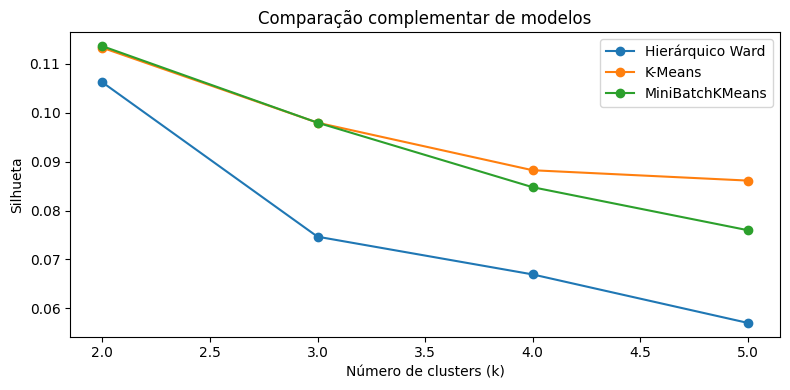

In [3]:
tabela_grafico = comparacao[['algoritmo', 'k', 'silhueta']].copy()
tabela_grafico.to_csv(TABELAS / '07_bonus_silhueta_grafico.csv', sep=';', index=False)
fig, ax = plt.subplots(figsize=(8, 4))
for nome, grupo in tabela_grafico.groupby('algoritmo'):
    ax.plot(grupo.sort_values('k')['k'], grupo.sort_values('k')['silhueta'], marker='o', label=nome)
ax.set(xlabel='Número de clusters (k)', ylabel='Silhueta', title='Comparação complementar de modelos')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / '07_bonus_silhueta.png', dpi=130)
plt.show()


## 3. Inspecionar o melhor resultado exploratório

Selecionamos o maior valor de silhueta **somente neste experimento bônus**. Isso não implica aprovação, nem altera o modelo do notebook 04.

In [4]:
melhor = comparacao.iloc[0]
nome = melhor['algoritmo']
k = int(melhor['k'])
if nome == 'K-Means':
    modelo_bonus = KMeans(n_clusters=k, n_init=10, random_state=42)
elif nome == 'MiniBatchKMeans':
    modelo_bonus = MiniBatchKMeans(n_clusters=k, batch_size=256, n_init=10, random_state=42)
else:
    modelo_bonus = AgglomerativeClustering(n_clusters=k, linkage='ward')

rotulos_bonus = modelo_bonus.fit_predict(X)
segmentados = perfil.copy()
segmentados['segmento_bonus'] = rotulos_bonus
colunas = ['Idade', 'Renda_Mensal', 'Anos_na_Empresa']
faltantes = [c for c in colunas if c not in segmentados.columns]
if faltantes:
    raise ValueError(f'Colunas necessárias para o perfil: {faltantes}')

perfil_bonus = segmentados.groupby('segmento_bonus').agg(
    colaboradores=('Idade', 'size'),
    idade_mediana=('Idade', 'median'),
    renda_mediana=('Renda_Mensal', 'median'),
    anos_empresa_mediana=('Anos_na_Empresa', 'median'),
).reset_index()
if 'Desligamento' in segmentados.columns:
    desliga = segmentados['Desligamento'].astype(str).str.strip().str.lower().isin(['sim'])
    perfil_bonus['taxa_desligamento'] = desliga.groupby(segmentados['segmento_bonus']).mean().to_numpy()

perfil_bonus.to_csv(TABELAS / '07_bonus_perfil_segmentos.csv', sep=';', index=False)
segmentados.to_csv(BASE / '07_bonus_colaboradores_segmentados.csv', sep=';', index=False)
joblib.dump(modelo_bonus, MODELOS / '07_bonus_modelo.joblib')
print(f'Experimento bônus: {nome}, k={k}, silhueta={melhor["silhueta"]:.4f}')
display(perfil_bonus.round(3))


Experimento bônus: MiniBatchKMeans, k=2, silhueta=0.1136


,segmento_bonus,colaboradores,idade_mediana,renda_mediana,anos_empresa_mediana,taxa_desligamento
0,0,1019,36.0,4325.0,5.0,0.141
1,1,451,35.0,5772.0,6.0,0.206


## 4. Discussão e encerramento

Preencha esta seção após executar o notebook com os artefatos definitivos:

- **Comparação:** o algoritmo com maior silhueta também apresentou bom Davies–Bouldin e Calinski–Harabasz? Houve grupos desproporcionais?
- **Interpretação:** as diferenças de idade, renda e tempo de empresa são compreensíveis? `Desligamento` foi usado apenas como variável descritiva externa.
- **Limitação:** os índices internos avaliam geometria no espaço preparado (MinMax + One-Hot); eles não demonstram utilidade operacional nem causalidade.
- **Conclusão:** este experimento é complementar. Qualquer alteração da solução oficial exige nova avaliação nos notebooks 04–06.

**Artefatos do experimento:** `07_bonus_comparacao.csv`, `07_bonus_silhueta_grafico.csv`, `07_bonus_silhueta.png`, `07_bonus_perfil_segmentos.csv`, `07_bonus_colaboradores_segmentados.csv` e `07_bonus_modelo.joblib`.
